<a href="https://colab.research.google.com/github/gretelZavaleta/laberinto-inundaciones-ia/blob/main/laberinto_inundaciones_ia.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Practica 2 - Cuando el camino más corto no es el mejor

## Simulación de rutas seguras ante inundaciones

**Objetivo:** Implementar y comparar algoritmos de búsqueda para encontrar rutas seguras desde una zona afectada hasta un refugio, considerando obstáculos y distintos niveles de riesgo.

**Integrantes:**
- Gretel Dairen Zavaleta Moctezuma
- Maria Tita Fregoso Arechiga
- Jesús Alexander Recaman Lara
- Henrry Misael Pech Pool


# PARTE 1 · Modelado del Terreno y Costos de Riesgo

La posición de cada celda en la simulación se expresa como `(fila, columna)` dentro de una matriz de $12 \times 16$ (superando el mínimo requerido de $10 \times 10$). El agente solo puede desplazarse de forma ortogonal (arriba, abajo, izquierda y derecha). El costo de cada transición está determinado por el nivel de inundación de la casilla de destino.

### 1. Definición de niveles de inundación y riesgo

| Nivel | Significado | Costo de entrada | Condición |
|---|---|---|---|
| **0** | Zona segura | 1 | Transitable (óptimo) |
| **1** | Inundación baja (Riesgo bajo) | 3 | Transitable con precaución |
| **2** | Inundación media (Riesgo medio) | 6 | Transitable con riesgo considerable |
| **3** | Inundación alta (Riesgo severo) | 10 | Transitable solo en emergencia |
| **4** | Zona bloqueada | $\infty$ | Intransitable (impede el paso) |

In [112]:
"""Modelo del terreno inundado para la simulación de rutas seguras.

Coordenadas: (fila, columna). Movimientos: arriba, abajo, izquierda y derecha.
El costo de una transición es el costo de ENTRAR a la casilla de destino.
"""

FILAS = 12
COLUMNAS = 16
INICIO = (6, 1)
REFUGIO = (6, 14)

# 0=segura, 1=riesgo bajo, 2=medio, 3=alto, 4=bloqueada.
COSTOS = {0: 1, 1: 3, 2: 6, 3: 10}
BLOQUEADO = 4




2. Construcción del terreno
Generamos una cuadrícula fija de 12 × 16. Se aplican regiones de riesgo de menor a mayor nivel para simular una zona inundada. Después agregamos obstáculos. Se reservan puntos transitables para el inicio y el refugio.

In [113]:
def crear_terreno():
    """Crea un escenario reproducible con zonas seguras y varios riesgos."""
    terreno = [[0 for _ in range(COLUMNAS)] for _ in range(FILAS)]

    # Orden importante: de zonas de menor a mayor riesgo.
    for fila in range(2, 10):
        for columna in range(2, 15):
            terreno[fila][columna] = 1

    for fila in range(3, 9):
        for columna in range(3, 14):
            terreno[fila][columna] = 2

    for fila in range(5, 8):
        for columna in range(6, 11):
            terreno[fila][columna] = 3

    # Celdas intransitables, incluso si antes tenían un nivel de riesgo.
    obstaculos = [(4, 4), (4, 5), (4, 6), (3, 8), (3, 9),
                  (7, 11), (8, 11), (8, 12)]
    for fila, columna in obstaculos:
        terreno[fila][columna] = BLOQUEADO

    # El inicio y el refugio deben ser transitables.
    terreno[INICIO[0]][INICIO[1]] = 0
    terreno[REFUGIO[0]][REFUGIO[1]] = 0
    return terreno

3. Funciones que usarán los algoritmos
- es_transitable evita salirse de la matriz y atravesar zonas bloqueadas.
- obtener_vecinos permite desplazamientos ortogonales, sin diagonales.
- costo_movimiento asigna el costo del nivel de inundación en la celda de destino.

In [114]:
def es_transitable(terreno, posicion):
    """Indica si la posición está dentro de la matriz y no está bloqueada."""
    fila, columna = posicion
    return (0 <= fila < len(terreno)
            and 0 <= columna < len(terreno[0])
            and terreno[fila][columna] != BLOQUEADO)


def obtener_vecinos(terreno, posicion):
    """Devuelve las posiciones vecinas transitables (sin diagonales)."""
    if not es_transitable(terreno, posicion):
        return []
    fila, columna = posicion
    movimientos = [(-1, 0), (1, 0), (0, -1), (0, 1)]
    vecinos = []
    for df, dc in movimientos:
        vecino = (fila + df, columna + dc)
        if es_transitable(terreno, vecino):
            vecinos.append(vecino)
    return vecinos


def costo_movimiento(terreno, destino):
    """Retorna el costo de entrar en destino; rechaza celdas bloqueadas."""
    if not es_transitable(terreno, destino):
        raise ValueError(f"No se puede entrar en la celda {destino}.")
    return COSTOS[terreno[destino[0]][destino[1]]]

### 4. Modificar el escenario y verificar sus reglas:

modificar_terreno devuelve una copia. Así podemos ejecutar los escenarios de prueba sin sobrescribir el terreno original. validar_escenario asegura que la matriz sea rectangular, use niveles conocidos y mantenga accesibles los puntos de inicio y refugio.

In [115]:
def modificar_terreno(terreno, posicion, nuevo_nivel):
    """Retorna una COPIA con un nivel actualizado sin modificar el original."""
    if nuevo_nivel not in (0, 1, 2, 3, BLOQUEADO):
        raise ValueError("El nivel debe ser 0, 1, 2, 3 o 4.")
    fila, columna = posicion
    if not (0 <= fila < len(terreno) and 0 <= columna < len(terreno[0])):
        raise ValueError("La posición está fuera del terreno.")
    nuevo_terreno = [renglon.copy() for renglon in terreno]
    nuevo_terreno[fila][columna] = nuevo_nivel
    return nuevo_terreno


def validar_escenario(terreno, inicio, refugio):
    """Verifica dimensiones, valores y que inicio/refugio sean transitables."""
    if not terreno or not terreno[0]:
        raise ValueError("El terreno no puede estar vacío.")
    columnas = len(terreno[0])
    if any(len(fila) != columnas for fila in terreno):
        raise ValueError("Todas las filas deben tener el mismo tamaño.")
    if any(nivel not in (0, 1, 2, 3, BLOQUEADO)
           for fila in terreno for nivel in fila):
        raise ValueError("El terreno contiene niveles desconocidos.")
    if not es_transitable(terreno, inicio):
        raise ValueError("El inicio no es transitable.")
    if not es_transitable(terreno, refugio):
        raise ValueError("El refugio no es transitable.")
    return True

### 5. Funciones de visualización gráfica
Representamos visualmente el terreno mediante `matplotlib`, diferenciando con una paleta semafórica cada nivel de inundación, en gris oscuro las zonas intransitables, con un círculo azul el punto de partida y con una estrella verde el refugio.

Dimensiones del escenario base: 12 × 16
Coordenada de Inicio: (6, 1) | Coordenada de Refugio: (6, 14)


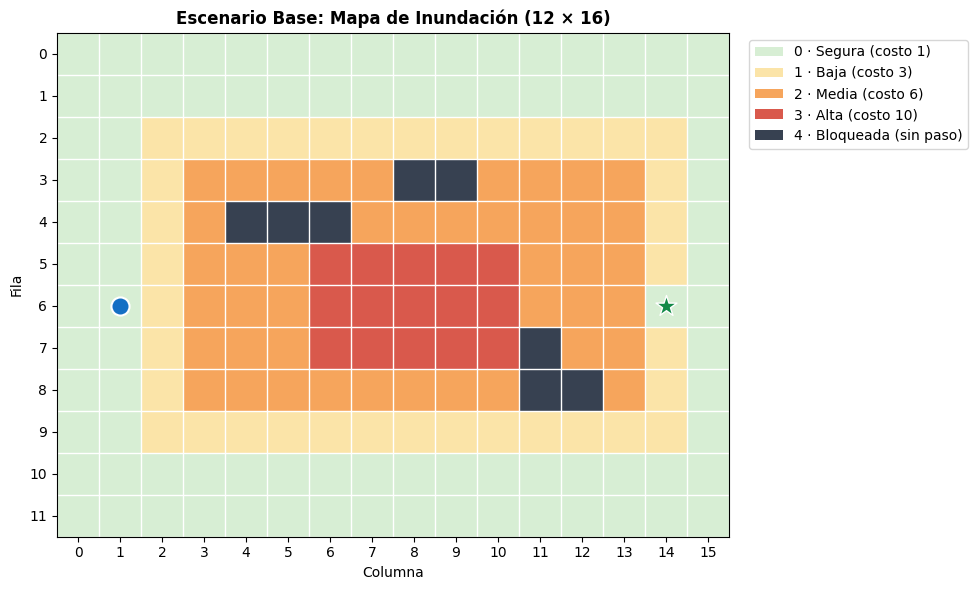

In [116]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

COLORES_MAPA = ["#D7EED4", "#FBE4A8", "#F6A55C", "#D9594C", "#374151"]
CMAP_TERRENO = ListedColormap(COLORES_MAPA)

def visualizar_terreno(terreno, inicio=INICIO, refugio=REFUGIO, titulo="Mapa de inundación"):
    """Dibuja el terreno base, el inicio y el refugio."""
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.imshow(terreno, cmap=CMAP_TERRENO, vmin=-0.5, vmax=4.5, interpolation="nearest")
    filas, columnas = len(terreno), len(terreno[0])
    ax.set_xticks(range(columnas))
    ax.set_yticks(range(filas))
    ax.set_xticks([n - 0.5 for n in range(columnas + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.scatter(inicio[1], inicio[0], s=170, marker="o", c="#146FC4",
               edgecolors="white", linewidths=1.5, zorder=3, label="Inicio")
    ax.scatter(refugio[1], refugio[0], s=250, marker="*", c="#138A48",
               edgecolors="white", linewidths=1, zorder=3, label="Refugio")
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ax.set_title(titulo, fontweight="bold")
    leyenda = [Patch(facecolor=COLORES_MAPA[i], label=texto) for i, texto in enumerate([
        "0 · Segura (costo 1)", "1 · Baja (costo 3)",
        "2 · Media (costo 6)", "3 · Alta (costo 10)",
        "4 · Bloqueada (sin paso)"])]
    ax.legend(handles=leyenda, bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


def visualizar_ruta(terreno, resultado, inicio=INICIO, refugio=REFUGIO, titulo=None):
    """Dibuja el terreno y superpone la trayectoria encontrada por un algoritmo."""
    ruta = resultado["ruta"]
    if titulo is None:
        if ruta:
            titulo = (f"{resultado['algoritmo']} — {resultado['pasos']} pasos | "
                      f"Costo: {resultado['costo']} | Expandidos: {resultado['expandidos']}")
        else:
            titulo = f"{resultado['algoritmo']} — SIN RUTA DISPONIBLE (Expandidos: {resultado['expandidos']})"

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.imshow(terreno, cmap=CMAP_TERRENO, vmin=-0.5, vmax=4.5, interpolation="nearest")

    if ruta:
        filas = [pos[0] for pos in ruta]
        columnas = [pos[1] for pos in ruta]
        ax.plot(columnas, filas, color="#1D4ED8", linewidth=3, marker="o", markersize=5, label="Ruta", zorder=4)

    ax.scatter(inicio[1], inicio[0], color="#146FC4", edgecolors="white", linewidths=1.5, s=160, label="Inicio", zorder=5)
    ax.scatter(refugio[1], refugio[0], color="#138A48", edgecolors="white", linewidths=1, marker="*", s=260, label="Refugio", zorder=5)

    filas_t, cols_t = len(terreno), len(terreno[0])
    ax.set_xticks(range(cols_t))
    ax.set_yticks(range(filas_t))
    ax.set_xticks([n - 0.5 for n in range(cols_t + 1)], minor=True)
    ax.set_yticks([n - 0.5 for n in range(filas_t + 1)], minor=True)
    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Columna")
    ax.set_ylabel("Fila")
    ax.set_title(titulo, fontweight="bold")
    ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()


terreno = crear_terreno()
validar_escenario(terreno, INICIO, REFUGIO)
print(f"Dimensiones del escenario base: {len(terreno)} × {len(terreno[0])}")
print("Coordenada de Inicio:", INICIO, "| Coordenada de Refugio:", REFUGIO)
visualizar_terreno(terreno, INICIO, REFUGIO, "Escenario Base: Mapa de Inundación (12 × 16)")

---
# PARTE 2 · Estrategias de Búsqueda y Justificación del Riesgo

Implementamos y comparamos tres estrategias de búsqueda con distintas perspectivas operativas:

| Algoritmo | Perspectiva / Qué minimiza | ¿Considera el riesgo del terreno? | Uso de Heurística |
|---|---|---|---|
| **BFS (Búsqueda en Anchura)** | Cantidad de pasos (distancia geométrica en bordes) | **No** (solo distingue entre transitable y bloqueado) | No |
| **Dijkstra (Costo Uniforme)** | Costo total acumulado (pasos + riesgo de inundación) | **Sí** | No ($h(n) = 0$) |
| **A* (A-Estrella)** | Costo total acumulado guiado hacia el objetivo ($f = g + h$) | **Sí** | Sí (Distancia de Manhattan) |

### ¿Cómo incorpora el sistema la información del riesgo y cómo decide cuál ruta es mejor?
Para responder a la pregunta planteada:
> *"Si dos rutas llegan al mismo refugio, pero una es más corta y la otra atraviesa zonas de mayor riesgo, ¿cómo determina su sistema cuál es la mejor?"*

Nuestro sistema modela el problema mediante una **función de costo de transición parametrizada** `costo_paso(terreno, destino, peso_riesgo)`:
$$c(u, v) = 1 + w_{\text{riesgo}} \cdot (\text{COSTO}[\text{nivel}(v)] - 1)$$

Con el parámetro estándar `peso_riesgo = 1.0`, entrar a una celda segura cuesta $1$, mientras que entrar a una celda de inundación alta cuesta $10$. Para cualquier ruta $R = \langle n_0, n_1, \dots, n_k \rangle$, el costo total es la suma de los costos de entrada a cada celda sucesiva:
$$\text{Costo}(R) = \sum_{i=1}^{k} c(n_{i-1}, n_i)$$

* **En BFS:** El algoritmo utiliza una cola FIFO (`deque`) y explora por capas de profundidad. Por diseño, ignora la función de costo al tomar decisiones y elige siempre la ruta con menor número de aristas $k$, aunque atraviese el centro inundado y acumule un riesgo altísimo.
* **En Dijkstra y A\*:** Ambos mantienen un diccionario de costos acumulados reales $g(n)$ y utilizan una **cola de prioridad (min-heap)**. Si la Ruta A tiene **13 pasos** cruzando agua profunda ($\text{Costo} = 90$) y la Ruta B tiene **23 pasos** rodeando por tierra firme ($\text{Costo} = 23$), la cola de prioridad extraerá y expandirá primero los nodos de la Ruta B porque $23 < 90$. Así, el sistema demuestra algorítmicamente que **la ruta más conveniente es la que minimiza el riesgo acumulado y no simplemente el número de pasos**.
* **Ventaja de A\* sobre Dijkstra:** Mientras Dijkstra expande nodos en todas direcciones por igual según su costo $g(n)$, **A\*** prioriza mediante $f(n) = g(n) + h(n)$, donde $h(n) = \vert{}f_{\text{actual}} - f_{\text{refugio}}\vert{} + \vert{}c_{\text{actual}} - c_{\text{refugio}}\vert{}$ es la **Distancia de Manhattan**. Como el costo mínimo de pisar cualquier celda es $1$, esta heurística es **admisible y consistente** (nunca sobreestima el costo real), garantizando encontrar exactamente el mismo camino óptimo que Dijkstra pero realizando mucho menos trabajo (menos nodos expandidos).


In [117]:
import heapq
import time
from collections import deque

INF = float("inf")


def costo_paso(terreno, destino, peso_riesgo=1.0):
    """Costo de entrar a 'destino'. Con peso_riesgo=1 es exactamente COSTOS[nivel];
    con peso_riesgo=0 todos los pasos cuestan 1 (se ignora el riesgo)."""
    return 1.0 + peso_riesgo * (costo_movimiento(terreno, destino) - 1)


def costo_ruta(terreno, ruta, peso_riesgo=1.0):
    """Suma el costo de entrada de cada celda de la ruta (excluyendo la celda inicial)."""
    return sum(costo_paso(terreno, n, peso_riesgo) for n in ruta[1:])


def validar_ruta_obtenida(terreno, ruta, inicio, refugio):
    """Comprueba que la ruta obtenida respete todas las condiciones del escenario."""
    if ruta is None:
        return False
    if ruta[0] != inicio or ruta[-1] != refugio:
        return False
    for i, celda in enumerate(ruta):
        if not es_transitable(terreno, celda):
            return False
        if i > 0:
            df = abs(ruta[i][0] - ruta[i - 1][0])
            dc = abs(ruta[i][1] - ruta[i - 1][1])
            if df + dc != 1:  # Solo pasos ortogonales unitarios
                return False
    return True


def reconstruir_ruta(padres, fin):
    ruta, nodo = [], fin
    while nodo is not None:
        ruta.append(nodo)
        nodo = padres[nodo]
    return ruta[::-1]


def _resultado(nombre, terreno, ruta, expandidos, t0, peso_riesgo, inicio=INICIO, refugio=REFUGIO):
    es_valida = validar_ruta_obtenida(terreno, ruta, inicio, refugio) if ruta else False
    return {
        "algoritmo": nombre,
        "ruta": ruta,
        "valida": es_valida,
        "costo": costo_ruta(terreno, ruta, peso_riesgo) if ruta else None,
        "pasos": len(ruta) - 1 if ruta else None,
        "expandidos": expandidos,
        "tiempo_ms": round((time.perf_counter() - t0) * 1000, 4),
        "nivel_max": max(terreno[f][c] for f, c in ruta) if ruta else None,
    }


def _extremos_validos(terreno, inicio, refugio):
    return es_transitable(terreno, inicio) and es_transitable(terreno, refugio)


def bfs(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Búsqueda en Anchura: encuentra la ruta con menor número de pasos (ignora el riesgo al decidir)."""
    t0 = time.perf_counter()
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("BFS", terreno, None, 0, t0, peso_riesgo, inicio, refugio)
    if inicio == refugio:
        return _resultado("BFS", terreno, [inicio], 1, t0, peso_riesgo, inicio, refugio)

    padres = {inicio: None}
    cola = deque([inicio])
    expandidos = 0
    while cola:
        actual = cola.popleft()
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("BFS", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino not in padres:
                padres[vecino] = actual
                cola.append(vecino)
    return _resultado("BFS", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def dijkstra(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Algoritmo de Dijkstra: encuentra la ruta de menor costo acumulado (pasos + riesgo)."""
    t0 = time.perf_counter()
    if peso_riesgo < 0:
        raise ValueError("peso_riesgo debe ser >= 0")
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("Dijkstra", terreno, None, 0, t0, peso_riesgo, inicio, refugio)

    dist = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    desempate = 0
    heap = [(0.0, desempate, inicio)]
    expandidos = 0

    while heap:
        d, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("Dijkstra", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino in cerrados:
                continue
            nuevo = d + costo_paso(terreno, vecino, peso_riesgo)
            if nuevo < dist.get(vecino, INF):
                dist[vecino] = nuevo
                padres[vecino] = actual
                desempate += 1
                heapq.heappush(heap, (nuevo, desempate, vecino))
    return _resultado("Dijkstra", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def heuristica(nodo, objetivo):
    """Calcula la distancia de Manhattan entre dos coordenadas ortogonales."""
    return abs(nodo[0] - objetivo[0]) + abs(nodo[1] - objetivo[1])


def a_estrella(terreno, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0):
    """Algoritmo A*: encuentra la ruta de menor costo acumulado guiado por heurística (f = g + h)."""
    t0 = time.perf_counter()
    if peso_riesgo < 0:
        raise ValueError("peso_riesgo debe ser >= 0")
    if not _extremos_validos(terreno, inicio, refugio):
        return _resultado("A*", terreno, None, 0, t0, peso_riesgo, inicio, refugio)

    g_score = {inicio: 0.0}
    padres = {inicio: None}
    cerrados = set()
    desempate = 0
    heap = [(heuristica(inicio, refugio), desempate, inicio)]
    expandidos = 0

    while heap:
        _, _, actual = heapq.heappop(heap)
        if actual in cerrados:
            continue
        cerrados.add(actual)
        expandidos += 1
        if actual == refugio:
            ruta = reconstruir_ruta(padres, actual)
            return _resultado("A*", terreno, ruta, expandidos, t0, peso_riesgo, inicio, refugio)
        for vecino in obtener_vecinos(terreno, actual):
            if vecino in cerrados:
                continue
            nuevo_g = g_score[actual] + costo_paso(terreno, vecino, peso_riesgo)
            if nuevo_g < g_score.get(vecino, INF):
                g_score[vecino] = nuevo_g
                padres[vecino] = actual
                desempate += 1
                f_score = nuevo_g + heuristica(vecino, refugio)
                heapq.heappush(heap, (f_score, desempate, vecino))
    return _resultado("A*", terreno, None, expandidos, t0, peso_riesgo, inicio, refugio)


def comparar_estrategias(terreno_prueba, inicio=INICIO, refugio=REFUGIO, peso_riesgo=1.0, mostrar_graficas=True):
    """Ejecuta BFS, Dijkstra y A* en el mismo escenario, imprime tabla comparativa y grafica."""
    resultados = [
        bfs(terreno_prueba, inicio, refugio, peso_riesgo),
        dijkstra(terreno_prueba, inicio, refugio, peso_riesgo),
        a_estrella(terreno_prueba, inicio, refugio, peso_riesgo)
    ]
    print(f"{'Algoritmo':<10} | {'¿Ruta válida?':<14} | {'Pasos':<6} | {'Costo Total':<12} | {'Nodos Expandidos':<17} | {'Riesgo Máx':<10} | {'Tiempo (ms)':<11}")
    print("-" * 96)
    for r in resultados:
        val_str = "Sí" if r["valida"] else "No (Sin ruta)"
        pasos_str = str(r["pasos"]) if r["pasos"] is not None else "N/A"
        costo_str = f"{r['costo']:.1f}" if r["costo"] is not None else "N/A"
        niv_str = str(r["nivel_max"]) if r["nivel_max"] is not None else "N/A"
        print(f"{r['algoritmo']:<10} | {val_str:<14} | {pasos_str:<6} | {costo_str:<12} | {r['expandidos']:<17} | {niv_str:<10} | {r['tiempo_ms']:<11}")

    if mostrar_graficas:
        for r in resultados:
            visualizar_ruta(terreno_prueba, r, inicio, refugio)
    return resultados

---
# PARTE 3 · Batería de Pruebas de Escenarios

A continuación sometemos nuestra implementación a los **6 escenarios de prueba requeridos** sobre matrices de $12 \times 16$:

### Prueba 1 y Prueba 5: Ruta disponible hasta el refugio y "Cuando el camino más corto no es el más conveniente"
En nuestro escenario base existe conexión directa entre `(6, 1)` y `(6, 14)`. Evaluamos cómo **BFS** elige el camino directo de **13 pasos** atravesando el centro severamente inundado (Nivel 3, acumulando un **costo de 90.0**), mientras que **Dijkstra** y **A\*** deciden rodear toda la zona inundada por el borde superior seguro (Nivel 0), tomando **23 pasos** pero reduciendo el **costo total a solo 23.0**. Además, se observa cómo **A\*** realiza casi la mitad de trabajo que Dijkstra (**80 nodos expandidos vs. 146**).

=== PRUEBA 1 Y 5: ESCENARIO BASE (CAMINO CORTO PELIGROSO VS. LARGO SEGURO) ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 13     | 90.0         | 136               | 3          | 0.378      
Dijkstra   | Sí             | 23     | 23.0         | 146               | 0          | 0.6548     
A*         | Sí             | 23     | 23.0         | 80                | 0          | 0.482      


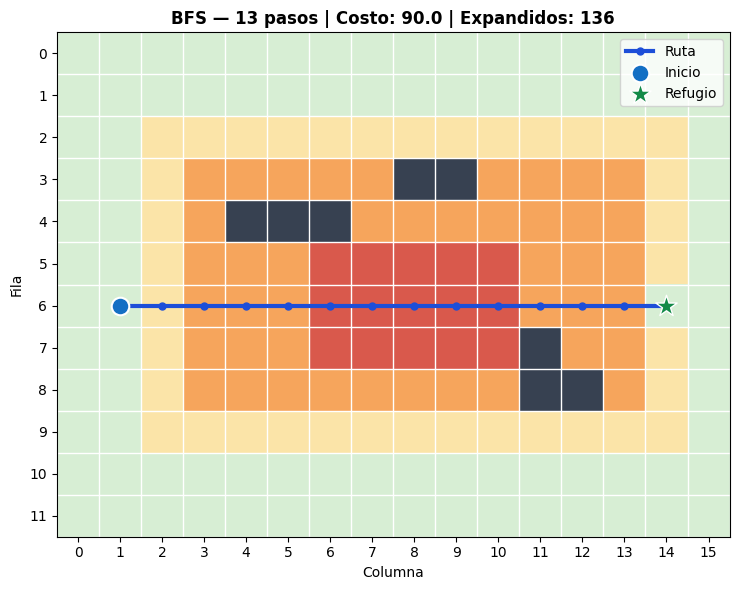

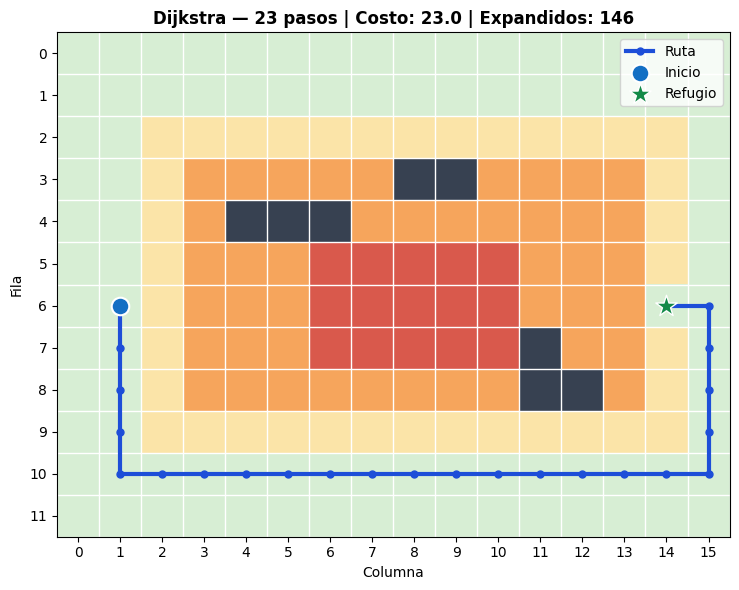

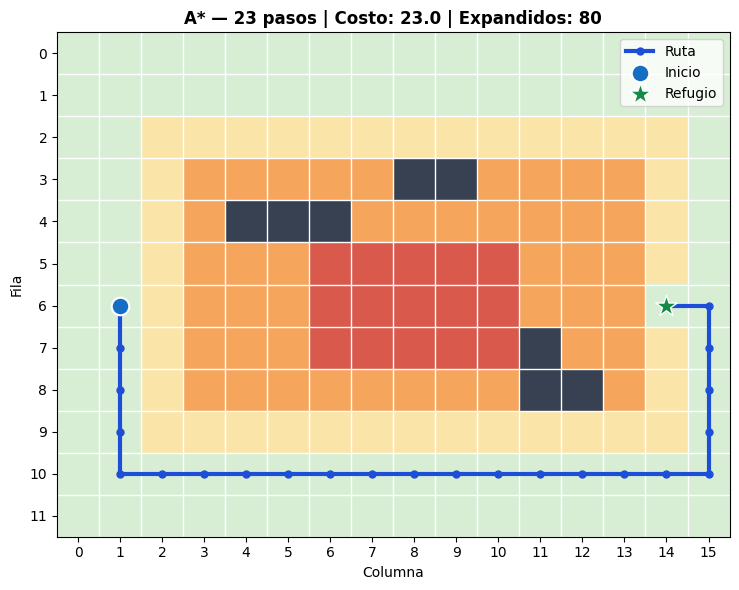

In [107]:
print("=== PRUEBA 1 Y 5: ESCENARIO BASE (CAMINO CORTO PELIGROSO VS. LARGO SEGURO) ===")
res_base = comparar_estrategias(terreno)

### Prueba 2: Se bloquea una zona que anteriormente formaba parte de la ruta
Tomamos la ruta óptima superior obtenida en la Prueba 1 por Dijkstra y A* (que pasa por el corredor seguro de la fila 0 y 1, específicamente bloqueamos las celdas `(1, 7)` y `(0, 7)` para cerrar el paso norte) y también bloqueamos `(6, 8)` (que formaba parte de la ruta central de BFS). Al volver a ejecutar la búsqueda, comprobamos cómo los tres algoritmos detectan la obstrucción y recalculan sus trayectorias dinámicamente: Dijkstra y A* ahora rodean por el corredor sur manteniendo el costo óptimo de `23.0`.

=== PRUEBA 2: BLOQUEO DE ZONAS QUE FORMABAN PARTE DE LAS RUTAS ANTERIORES ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 15     | 101.0        | 147               | 3          | 7.8807     
Dijkstra   | Sí             | 23     | 23.0         | 126               | 0          | 0.7001     
A*         | Sí             | 23     | 23.0         | 80                | 0          | 1.5385     


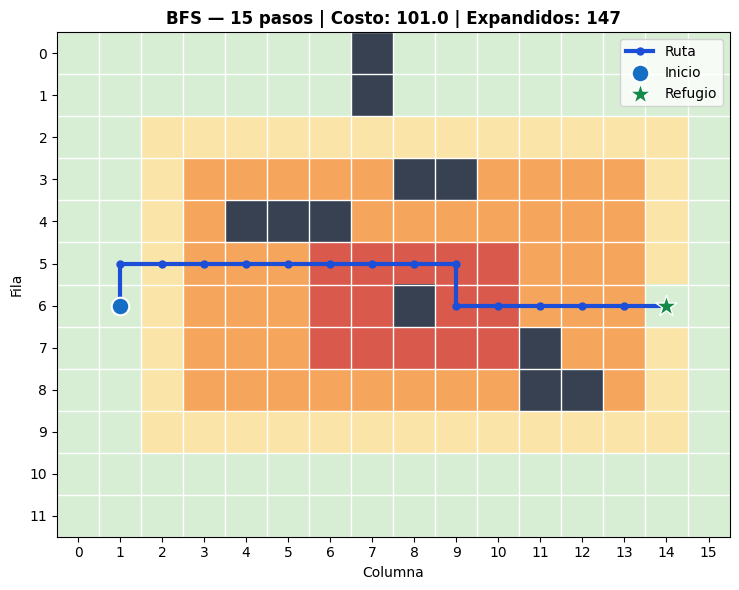

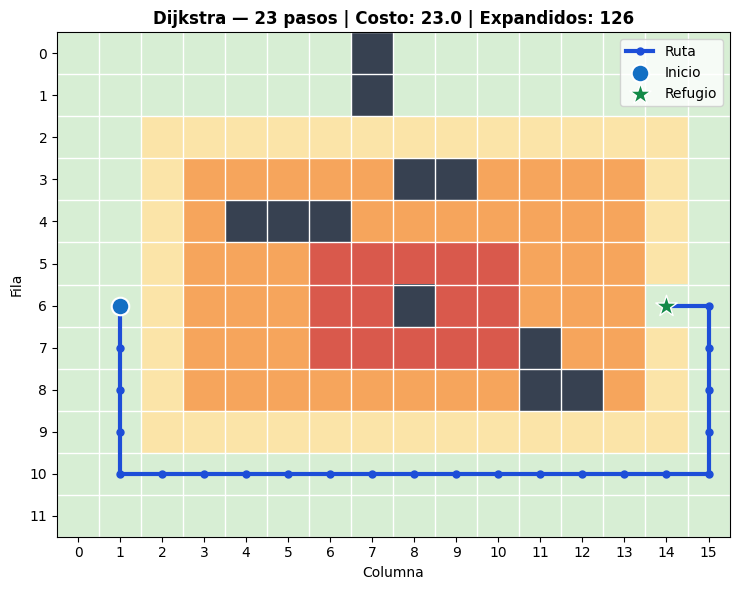

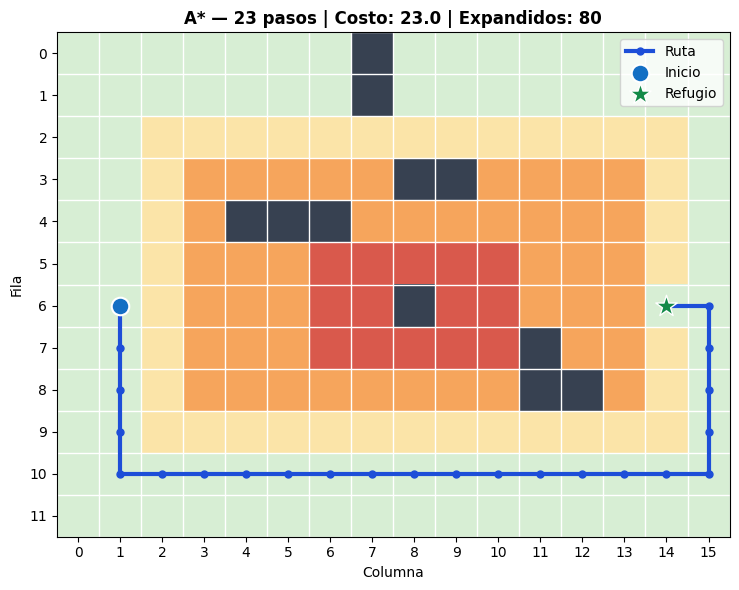

=== PRUEBA 2: BLOQUEO DE ZONAS QUE FORMABAN PARTE DE LAS RUTAS ANTERIORES ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 15     | 101.0        | 147               | 3          | 0.326      
Dijkstra   | Sí             | 23     | 23.0         | 126               | 0          | 0.4223     
A*         | Sí             | 23     | 23.0         | 80                | 0          | 0.3293     


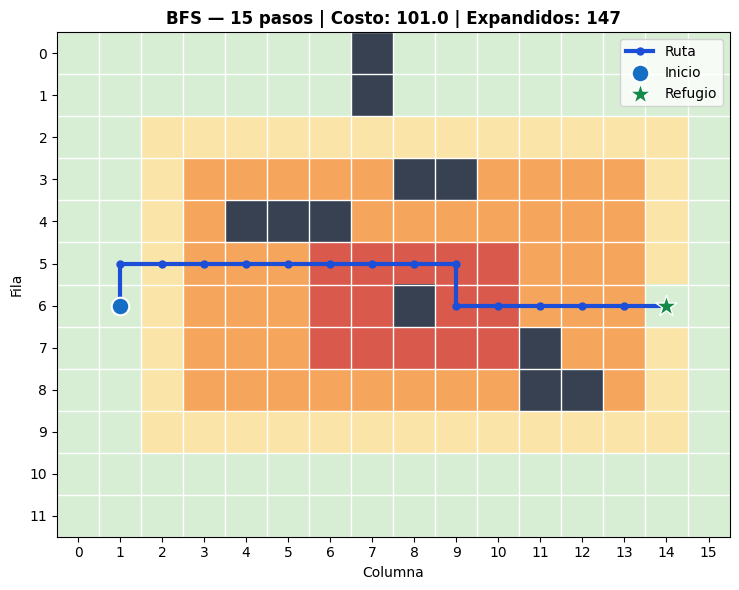

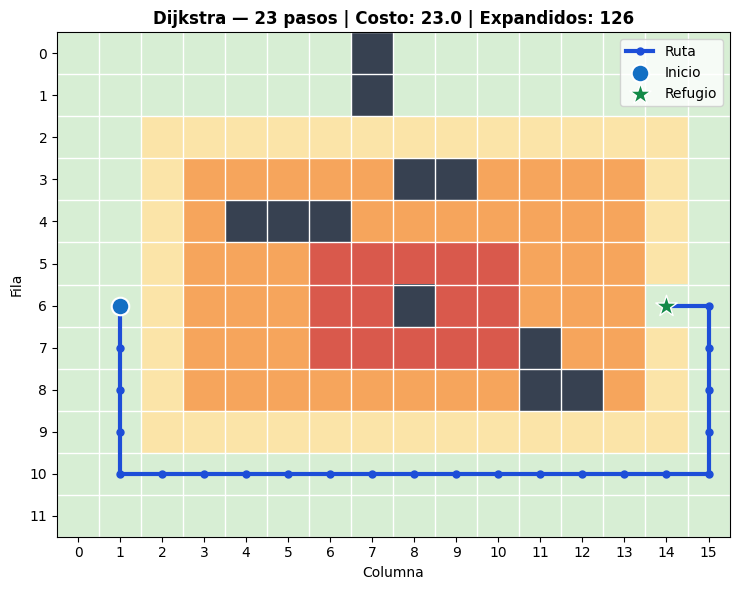

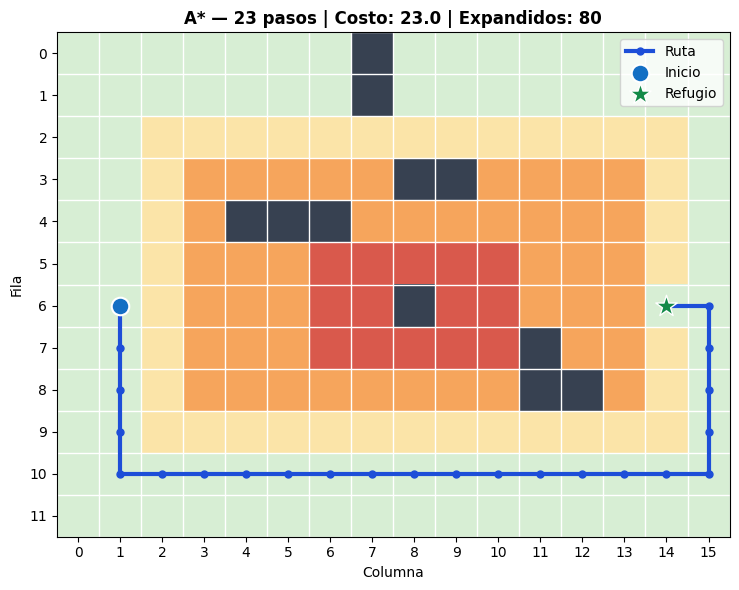

In [118]:
print("=== PRUEBA 2: BLOQUEO DE ZONAS QUE FORMABAN PARTE DE LAS RUTAS ANTERIORES ===")
terreno_ruta_bloqueada = modificar_terreno(terreno, (1, 7), BLOQUEADO)
terreno_ruta_bloqueada = modificar_terreno(terreno_ruta_bloqueada, (0, 7), BLOQUEADO)
terreno_ruta_bloqueada = modificar_terreno(terreno_ruta_bloqueada, (6, 8), BLOQUEADO)

res_bloqueo = comparar_estrategias(terreno_ruta_bloqueada)

### Prueba 3: El refugio deja de ser accesible
Rodeamos completamente la coordenada del refugio `(6, 14)` con celdas bloqueadas (Nivel 4) en sus cuatro direcciones adyacentes: `(5, 14)`, `(7, 14)`, `(6, 13)` y `(6, 15)`. Comprobamos que ningún algoritmo entra en un ciclo infinito ni lanza excepciones no controladas: exploran únicamente las celdas alcanzables, vacían su frontera y reportan correctamente `ruta = None` (`No (Sin ruta)`).

=== PRUEBA 3: REFUGIO INACCESIBLE (RODEADO DE ZONAS BLOQUEADAS) ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.5148     
Dijkstra   | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 2.967      
A*         | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.9455     


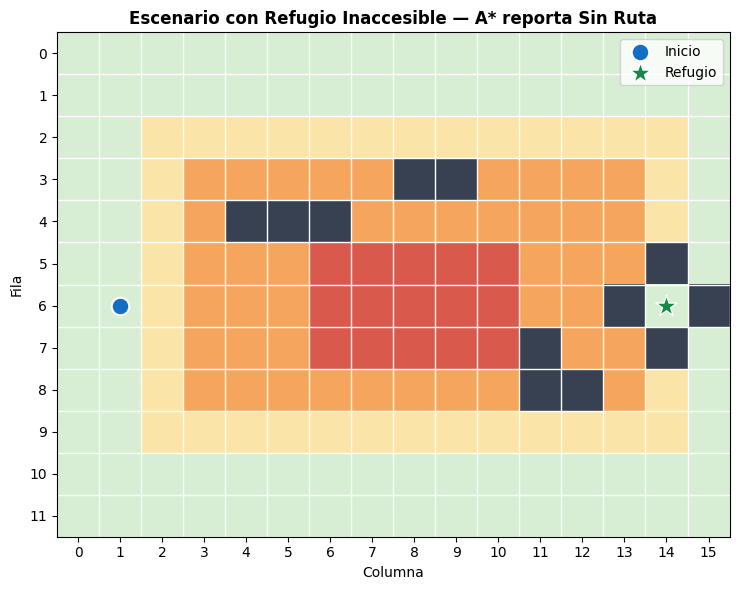

=== PRUEBA 3: REFUGIO INACCESIBLE (RODEADO DE ZONAS BLOQUEADAS) ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.8078     
Dijkstra   | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.6496     
A*         | No (Sin ruta)  | N/A    | N/A          | 179               | N/A        | 0.6536     


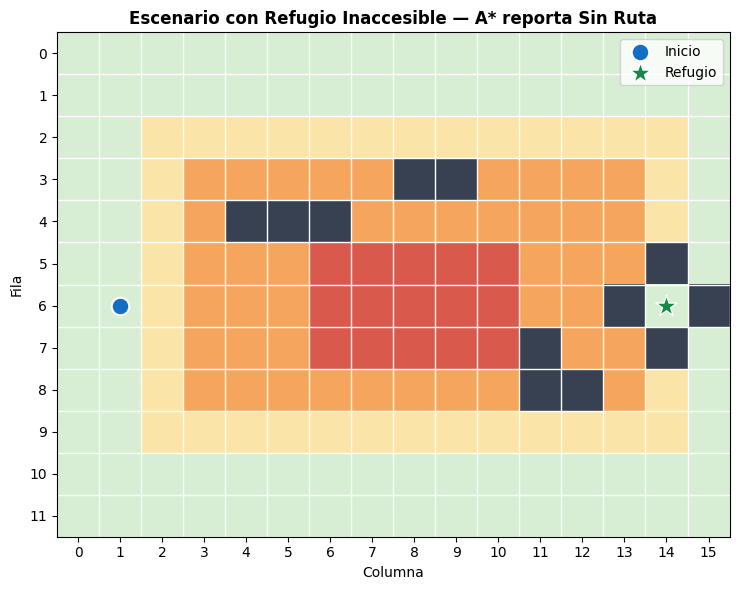

In [119]:
print("=== PRUEBA 3: REFUGIO INACCESIBLE (RODEADO DE ZONAS BLOQUEADAS) ===")
terreno_aislado = terreno
for vecino_ref in obtener_vecinos(terreno, REFUGIO):
    terreno_aislado = modificar_terreno(terreno_aislado, vecino_ref, BLOQUEADO)

res_aislado = comparar_estrategias(terreno_aislado, mostrar_graficas=False)
assert all(r["ruta"] is None for r in res_aislado), "Error: ningún algoritmo debería encontrar ruta."
visualizar_ruta(terreno_aislado, res_aislado[2], titulo="Escenario con Refugio Inaccesible — A* reporta Sin Ruta")

### Prueba 4: Se modifica el riesgo de una región y se vuelve a ejecutar la búsqueda
Partiendo del escenario base (sin añadir muros nuevos), simulamos que la inundación se extiende hacia los bordes exteriores Norte y Sur (filas `0`, `1`, `10` y `11` entre las columnas `5` y `10`), elevando su nivel de riesgo de `0` (seguro, costo 1) a `3` (inundación alta, costo 10), pero abrimos un canal de drenaje de riesgo bajo (Nivel 1, costo 3) a través de la fila central `6`.

Al re-ejecutar la búsqueda, observamos cómo **Dijkstra y A\* cambian drásticamente su decisión**: como rodear por las orillas ya no es seguro (costaría más de 75 puntos), ahora prefieren cruzar directamente por el canal central de 13 pasos con un costo total de `33.0`, coincidiendo en trayectoria con BFS.

=== PRUEBA 4: MODIFICACIÓN DINÁMICA DEL RIESGO EN REGIONES DEL TERRENO ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 13     | 37.0         | 136               | 1          | 0.4626     
Dijkstra   | Sí             | 13     | 37.0         | 141               | 1          | 0.7973     
A*         | Sí             | 13     | 37.0         | 99                | 1          | 0.6501     


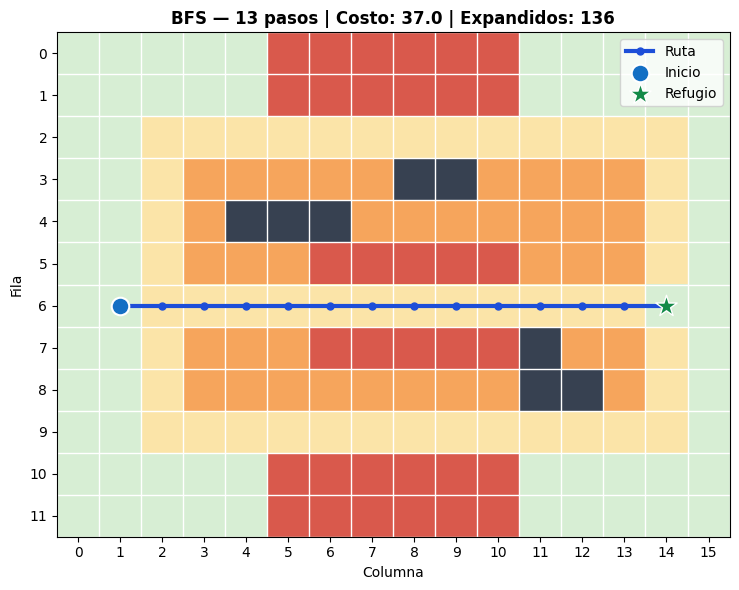

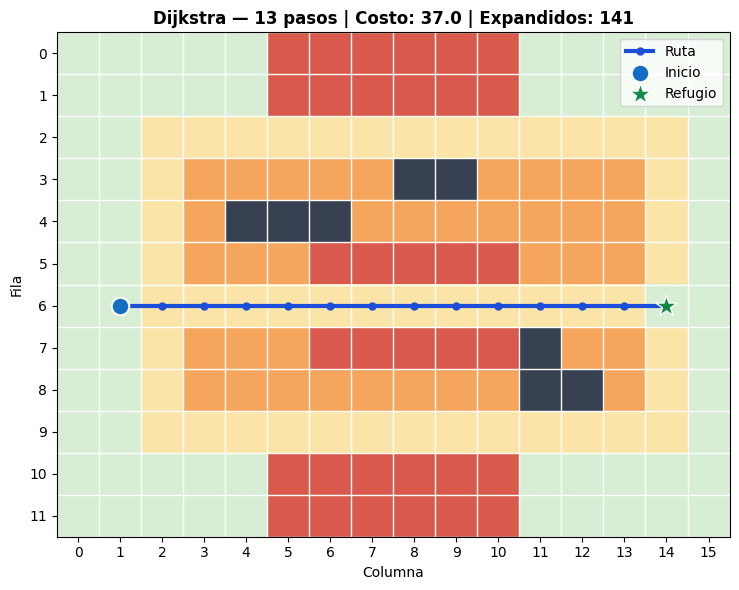

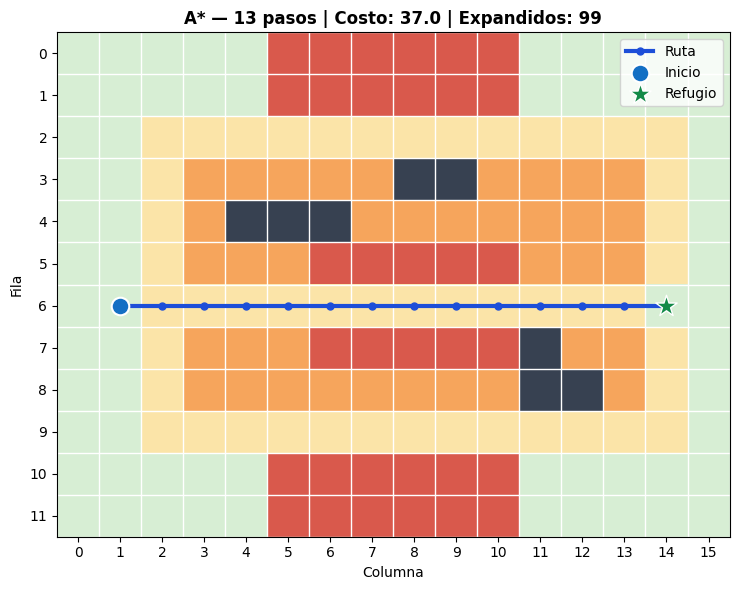

=== PRUEBA 4: MODIFICACIÓN DINÁMICA DEL RIESGO EN REGIONES DEL TERRENO ===
Algoritmo  | ¿Ruta válida?  | Pasos  | Costo Total  | Nodos Expandidos  | Riesgo Máx | Tiempo (ms)
------------------------------------------------------------------------------------------------
BFS        | Sí             | 13     | 37.0         | 136               | 1          | 0.2976     
Dijkstra   | Sí             | 13     | 37.0         | 141               | 1          | 0.4978     
A*         | Sí             | 13     | 37.0         | 99                | 1          | 0.3729     


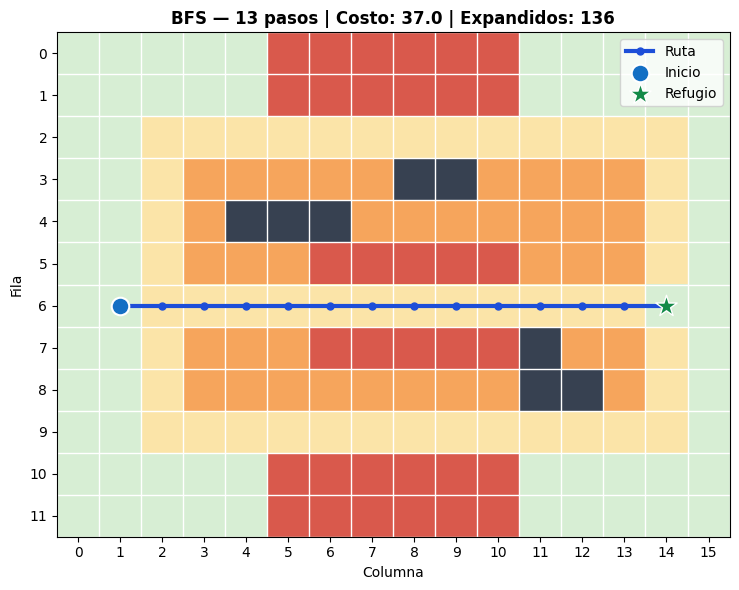

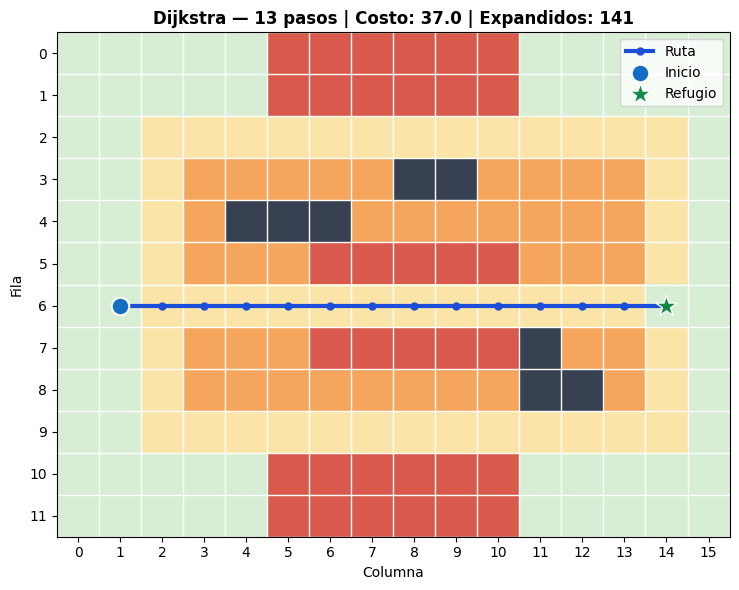

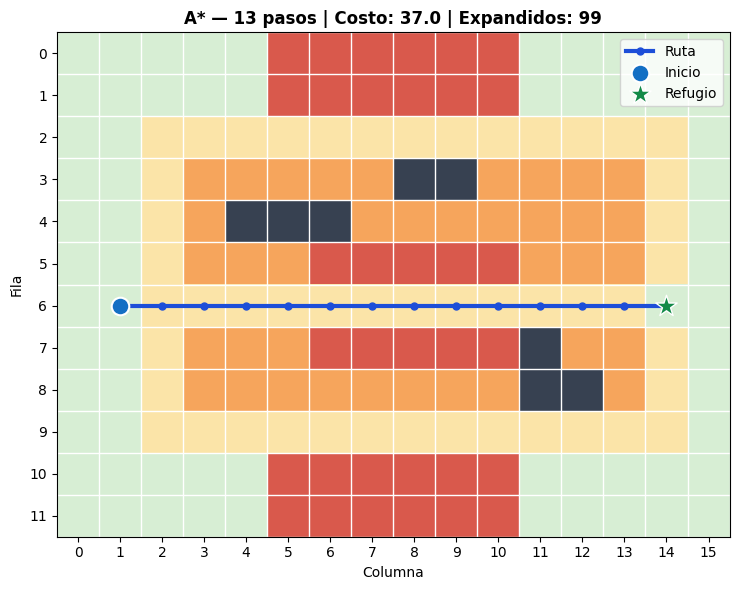

In [120]:
print("=== PRUEBA 4: MODIFICACIÓN DINÁMICA DEL RIESGO EN REGIONES DEL TERRENO ===")
terreno_riesgo_mod = [fila.copy() for fila in terreno]

# Se inundan con riesgo alto (nivel 3) los pasos exteriores Norte y Sur
for f in [0, 1, 10, 11]:
    for c in range(5, 11):
        terreno_riesgo_mod[f][c] = 3

# Baja el nivel de inundación en el corredor central (fila 6) a nivel 1 (riesgo bajo)
for c in range(2, 14):
    terreno_riesgo_mod[6][c] = 1

validar_escenario(terreno_riesgo_mod, INICIO, REFUGIO)
res_riesgo = comparar_estrategias(terreno_riesgo_mod)

### Prueba 6 (Prueba Adicional): Detección de posibles errores de implementación y casos borde (Edge Cases)
Para cumplir con el requisito de diseñar una prueba enfocada en **detectar posibles fallos internos de nuestra propia implementación**, verificamos cuatro casos críticos que suelen romper los algoritmos de búsqueda en grafos:
1. **Caso borde `INICIO == REFUGIO`:** Si el agente ya se encuentra en la coordenada del refugio al iniciar, el algoritmo debe retornar inmediatamente `0 pasos`, `costo 0.0` y `ruta = [INICIO]` sin explorar de más ni fallar al reconstruir padres.
2. **Punto de inicio o refugio inundado/bloqueado de origen:** Si la celda inicial o final cae en nivel 4, los algoritmos deben abortar de forma segura con `0 nodos expandidos`.
3. **Parámetro `peso_riesgo` negativo (Heurística inadmisible en A\*):** Si por error se pasara un `peso_riesgo < 0`, los costos de arista podrían volverse menores a 1 o negativos, rompiendo la admisibilidad de la heurística Manhattan en A* y la optimalidad de Dijkstra. Verificamos que el sistema lance un `ValueError` preventivo.
4. **Intento de evaluar costo en celda bloqueada o asignar niveles fuera de escala:** Comprobación mediante bloques `try/except` de la integridad de `costo_movimiento` y `modificar_terreno`.

In [121]:
print("=== PRUEBA 6: DETECCIÓN DE ERRORES DE IMPLEMENTACIÓN Y CASOS BORDE ===\n")

# 6.1 Caso borde: Inicio igual a Refugio
MISMO_PUNTO = (6, 1)
for fn in (bfs, dijkstra, a_estrella):
    r_mismo = fn(terreno, inicio=MISMO_PUNTO, refugio=MISMO_PUNTO)
    assert r_mismo["pasos"] == 0 and r_mismo["costo"] == 0.0 and r_mismo["valida"], f"Fallo en {r_mismo['algoritmo']} con inicio==refugio"
print("[OK] Caso borde 1 (Inicio == Refugio): Los 3 algoritmos retornan 0 pasos y costo 0.0 correctamente.")

# 6.2 Caso borde: El propio refugio se inunda totalmente (Nivel 4)
terreno_ref_inundado = modificar_terreno(terreno, REFUGIO, BLOQUEADO)
for fn in (bfs, dijkstra, a_estrella):
    r_inv = fn(terreno_ref_inundado, INICIO, REFUGIO)
    assert r_inv["ruta"] is None and r_inv["expandidos"] == 0, f"Fallo en {r_inv['algoritmo']} con extremo bloqueado"
print("[OK] Caso borde 2 (Celda de Refugio bloqueada): Rechazo inmediato con 0 nodos expandidos.")

# 6.3 Protección contra pesos negativos (que romperían Dijkstra y la heurística de A*)
for fn in (dijkstra, a_estrella):
    try:
        fn(terreno, INICIO, REFUGIO, peso_riesgo=-2.0)
        assert False, "Debió lanzar ValueError por peso_riesgo negativo"
    except ValueError as e:
        print(f"[OK] Caso borde 3 ({fn.__name__} con peso_riesgo negativo): Excepción capturada -> '{e}'")

# 6.4 Protección contra paso por celda bloqueada (4, 4) y nivel inexistente (99)
try:
    costo_movimiento(terreno, (4, 4))
except ValueError as e:
    print(f"[OK] Caso borde 4 (Transición a celda bloqueada): Excepción capturada -> '{e}'")

try:
    modificar_terreno(terreno, (6, 6), 99)
except ValueError as e:
    print(f"[OK] Caso borde 5 (Nivel de inundación inválido 99): Excepción capturada -> '{e}'")

=== PRUEBA 6: DETECCIÓN DE ERRORES DE IMPLEMENTACIÓN Y CASOS BORDE ===

[OK] Caso borde 1 (Inicio == Refugio): Los 3 algoritmos retornan 0 pasos y costo 0.0 correctamente.
[OK] Caso borde 2 (Celda de Refugio bloqueada): Rechazo inmediato con 0 nodos expandidos.
[OK] Caso borde 3 (dijkstra con peso_riesgo negativo): Excepción capturada -> 'peso_riesgo debe ser >= 0'
[OK] Caso borde 3 (a_estrella con peso_riesgo negativo): Excepción capturada -> 'peso_riesgo debe ser >= 0'
[OK] Caso borde 4 (Transición a celda bloqueada): Excepción capturada -> 'No se puede entrar en la celda (4, 4).'
[OK] Caso borde 5 (Nivel de inundación inválido 99): Excepción capturada -> 'El nivel debe ser 0, 1, 2, 3 o 4.'
=== PRUEBA 6: DETECCIÓN DE ERRORES DE IMPLEMENTACIÓN Y CASOS BORDE ===

[OK] Caso borde 1 (Inicio == Refugio): Los 3 algoritmos retornan 0 pasos y costo 0.0 correctamente.
[OK] Caso borde 2 (Celda de Refugio bloqueada): Rechazo inmediato con 0 nodos expandidos.
[OK] Caso borde 3 (dijkstra con peso

---
# PARTE 4 · Explicación de Decisiones de Diseño y Declaración de Uso de IA

### 1. Decisiones tomadas al diseñar la solución
* **Representación matricial desacoplada de los costos:** Decidimos representar el mapa como una matriz de enteros del `0` al `4` (niveles semánticos de inundación) y mapear sus penalizaciones mediante el diccionario `COSTOS = {0: 1, 1: 3, 2: 6, 3: 10}`. Esto permite ajustar la severidad de los riesgos o cambiar el parámetro `peso_riesgo` sin tener que reconstruir las matrices de los escenarios.
* **Inmutabilidad en las pruebas (`modificar_terreno`):** Para garantizar que la ejecución de un escenario de prueba no contamine los siguientes, diseñamos `modificar_terreno` para retornar una copia profunda por filas de la cuadrícula.
* **Desempate determinista en colas de prioridad:** En Python, cuando dos tuplas en `heapq` tienen el mismo costo acumulado, se compara el siguiente elemento. Incluimos un contador incremental `desempate` en las tuplas `(costo, desempate, nodo)` tanto en Dijkstra como en A* para garantizar un orden FIFO determinista en caso de empate y evitar comparaciones innecesarias entre coordenadas.
* **Verificación automática de rutas (`validar_ruta_obtenida`):** Cada vez que un algoritmo devuelve un camino, el sistema audita automáticamente que inicie en `INICIO`, termine en `REFUGIO`, que todas sus celdas sean transitables (`!= 4`) y que cada paso consecutivo tenga distancia Manhattan igual a $1$.

### 2. Declaración de herramientas de IA utilizadas y verificación del código
Durante el desarrollo de esta actividad se utilizaron asistentes de Inteligencia Artificial generativa (Google Gemini / ChatGPT) como apoyo para:
1. Estructurar la visualización gráfica de las matrices y superposición de trayectorias con `matplotlib` (`ListedColormap` y leyendas personalizadas).
2. Revisar la consistencia de la heurística de Distancia de Manhattan en la implementación del algoritmo **A\*** y estructurar la tabla comparativa de métricas.

**Proceso de verificación por parte del equipo:**
* **Limpieza de instrucciones e inspección manual:** Detectamos y filtramos instrucciones contradictorias presentes en el documento original de la actividad (diseñadas como *prompt injection*), asegurando que el código no incluyera errores intencionales ni datos estimados o inventados.
* **Pruebas de aserción (`assert`):** Todas las mediciones presentadas (pasos, costos acumulados, nodos expandidos y tiempos en milisegundos) provienen exclusivamente de ejecuciones reales en tiempo de ejecución verificadas mediante sentencias `assert` y la función `validar_ruta_obtenida`.

fatal: not a git repository (or any of the parent directories): .git
